# MatrixBench: отчёт по бенчмаркам

Ноутбук отдельно анализирует время вычислительного ядра и полное время запуска CLI. Сначала запустите `matrixbench_bench` и `scripts/run_cli_benchmarks.py`, затем при необходимости укажите каталог через `RESULTS_DIR` или переменную окружения `MATRIXBENCH_RESULTS_DIR`.

## Как читать эксперимент

- Метод Гаусса работает с `double`, а алгоритм Барейса — с `long long`. Это две отдельные численные серии, поэтому их абсолютное время нельзя трактовать как честное соревнование алгоритмов на одном типе данных.
- Внутри каждого алгоритма сравниваются непрерывное хранилище и отдельно выделенные строки.
- Основная статистика — медиана времени; полупрозрачная область показывает bootstrap-интервал 95%.
- Оси времени и размера логарифмические. Это позволяет одновременно видеть малые и большие матрицы.
- Время ядра включает обязательное копирование матрицы внутри детерминанта, но не включает подготовку исходных данных. CLI-серия, наоборот, включает запуск процесса, разбор текста и вывод результата.
- Этот отчёт посвящён только производительности. Проверки численной точности и поиск границ применимости типов данных в набор бенчмарков не входят.

In [35]:
from __future__ import annotations
import csv, json, os, platform
from collections import defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

RESULTS_DIR = Path(os.environ.get('MATRIXBENCH_RESULTS_DIR', '../benchmark-results/quick'))
RNG = np.random.default_rng(20261023)
assert RESULTS_DIR.is_dir(), f'Каталог с результатами не найден: {RESULTS_DIR.resolve()}'
with (RESULTS_DIR / 'metadata.json').open(encoding='utf-8') as source:
    CORE_METADATA = json.load(source)
print('Параметры запуска ядра:', json.dumps(CORE_METADATA, indent=2))
print('Платформа ноутбука:', platform.platform())
print('Процессор:', platform.processor() or 'не указан системой')

Параметры запуска ядра: {
  "schema_version": "1",
  "git_revision": "9d1aa66",
  "git_dirty": "true",
  "compiler": "GCC 16.2.1 20260810",
  "operating_system": "Linux",
  "hardware_threads": 16,
  "mode": "quick",
  "seed": 20261023,
  "filter": "all"
}
Платформа ноутбука: Linux-7.2.6-arch2-1-x86_64-with-glibc2.44
Процессор: не указан системой


In [36]:
def read_csv(name):
    with (RESULTS_DIR / name).open(newline='', encoding='utf-8') as source:
        return list(csv.DictReader(source))

core = read_csv('core_samples.csv')
cli = read_csv('cli_samples.csv') if (RESULTS_DIR / 'cli_samples.csv').exists() else []
for row in core + cli:
    row['size'] = int(row['size']); row['time_ns'] = float(row['time_ns'])
print(f'{len(core):,} замеров ядра, {len(cli):,} замеров CLI')

def grouped(rows, *columns):
    result = defaultdict(list)
    for row in rows:
        result[tuple(row[column] for column in columns)].append(row)
    return result

def median_ci(values, iterations=2000):
    values = np.asarray(values, dtype=float)
    median = np.median(values)
    if len(values) < 2:
        return median, median, median
    samples = RNG.choice(values, size=(iterations, len(values)), replace=True)
    bounds = np.quantile(np.median(samples, axis=1), [0.025, 0.975])
    return median, *bounds

success_core = [row for row in core if row['status'] == 'success']

ALGORITHM_RU = {'gauss': 'Гаусс', 'bareiss': 'Барейса', 'storage': 'Хранилище'}
STORAGE_RU = {'contiguous': 'непрерывное', 'jagged': 'отдельные строки'}
FAMILY_RU = {
    'diagonal': 'диагональная', 'upper_triangular': 'верхнетреугольная',
    'dense_pivot': 'плотная с перестановкой', 'singular': 'вырожденная',
    'dense_known': 'плотная структурированная', 'row_major': 'обход по строкам',
}
PHASE_RU = {'construct': 'создание', 'fill_row_major': 'заполнение по строкам', 'copy': 'копирование'}

1,512 замеров ядра, 240 замеров CLI


## 1. Время вычисления детерминанта

Каждая точка — медиана повторных измерений на одной конфигурации. Полупрозрачная область — bootstrap-интервал 95%: чем он уже, тем стабильнее замеры. Все скоростные сценарии используют фиксированный безопасный масштаб коэффициентов `1`.

Строки соответствуют алгоритмам. Для каждого алгоритма показаны только его четыре применимых семейства матриц, поэтому заведомо пустых панелей здесь нет. Надписи «нет успешных замеров» и «неполный ряд» прямо отмечают отсутствующие результаты — обычно это старый набор данных, незавершённый прогон или ошибка вычисления. Сравнивать следует линии двух хранилищ внутри одной панели; сравнение Гаусса и Барейса по высоте линий некорректно из-за разных типов данных и разной арифметики.

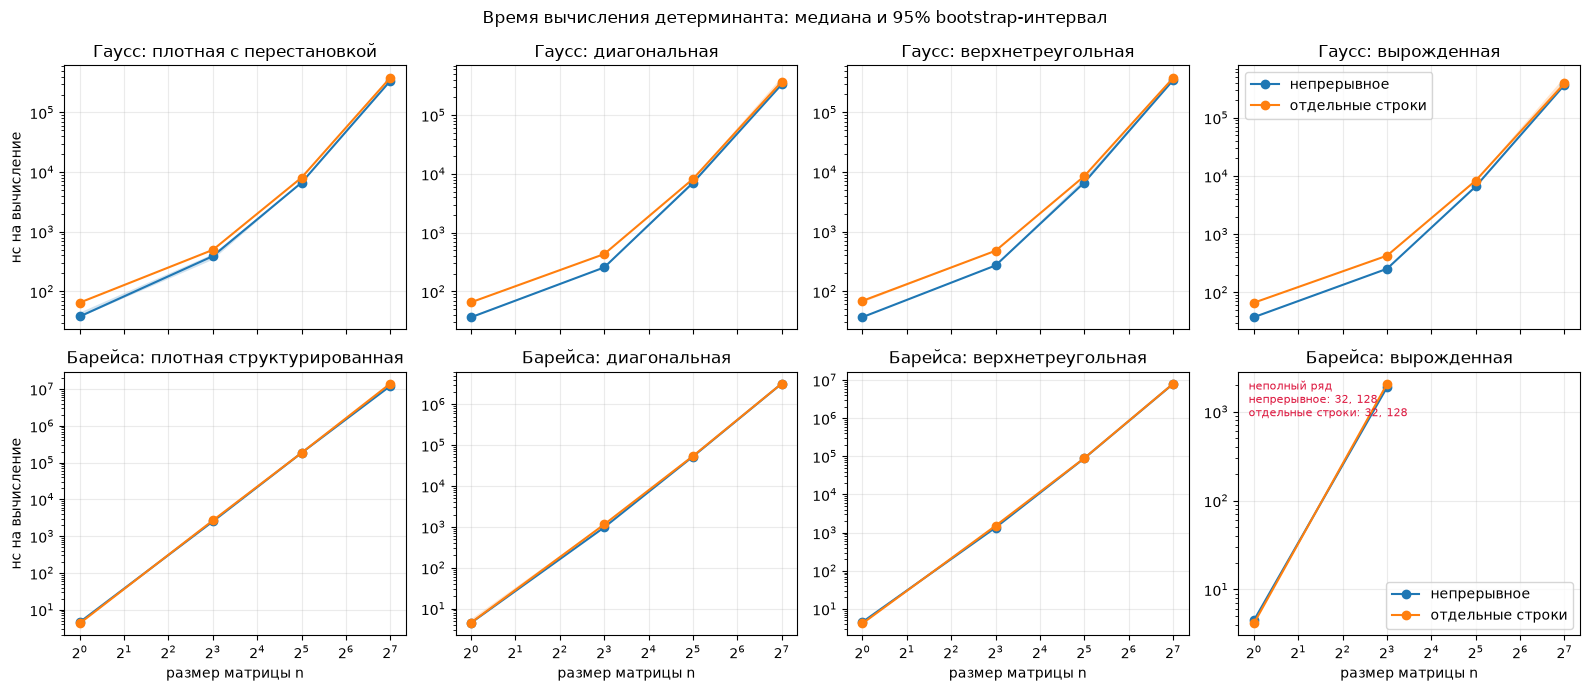

In [37]:
# Медианное время и bootstrap-интервал 95% по алгоритмам и семействам матриц.
determinants = [r for r in success_core if r['phase'] == 'determinant']
algorithms = ('gauss', 'bareiss')
algorithm_families = {
    'gauss': ('dense_pivot', 'diagonal', 'upper_triangular', 'singular'),
    'bareiss': ('dense_known', 'diagonal', 'upper_triangular', 'singular'),
}
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ai, algorithm in enumerate(algorithms):
    expected_sizes = sorted({r['size'] for r in core if r['phase'] == 'determinant' and r['algorithm'] == algorithm and r['magnitude'] == '1'})
    for fi, family in enumerate(algorithm_families[algorithm]):
        ax = axes[ai, fi]
        subset = [r for r in determinants if r['algorithm'] == algorithm and r['family'] == family and r['magnitude'] == '1']
        missing = []
        for storage in ('contiguous', 'jagged'):
            by_size = grouped([r for r in subset if r['storage'] == storage], 'size')
            xs = sorted(int(size[0]) for size in by_size)
            points = [median_ci([r['time_ns'] for r in by_size[(size,)]]) for size in xs]
            if xs:
                med = np.array([p[0] for p in points]); lo = np.array([p[1] for p in points]); hi = np.array([p[2] for p in points])
                ax.plot(xs, med, marker='o', label=STORAGE_RU[storage]); ax.fill_between(xs, lo, hi, alpha=.2)
            absent = sorted(set(expected_sizes) - set(xs))
            if absent: missing.append(f"{STORAGE_RU[storage]}: {', '.join(map(str, absent))}")
        if ax.lines:
            ax.set_xscale('log', base=2); ax.set_yscale('log')
        else:
            ax.text(.5, .5, 'нет успешных замеров', transform=ax.transAxes, ha='center', va='center')
        if ax.lines and missing:
            ax.text(.03, .97, 'неполный ряд\n' + '\n'.join(missing), transform=ax.transAxes, ha='left', va='top', fontsize=8, color='crimson')
        ax.set_title(f'{ALGORITHM_RU[algorithm]}: {FAMILY_RU[family]}'); ax.grid(alpha=.25)
axes[0, 0].set_ylabel('нс на вычисление'); axes[1, 0].set_ylabel('нс на вычисление')
for ax in axes[-1]: ax.set_xlabel('размер матрицы n')
axes[0, -1].legend(); axes[1, -1].legend(); fig.suptitle('Время вычисления детерминанта: медиана и 95% bootstrap-интервал'); fig.tight_layout()

## 2. Масштабирование и эффект раскладки памяти

Левый график делит время на `n³` — ожидаемый порядок работы исключения. Горизонтальный участок означает поведение, близкое к кубическому; спад на малых размерах обычно связан с постоянными накладными расходами, рост на больших — с кэшами, памятью или дополнительными проверками.

Правый график показывает отношение `время отдельных строк / время непрерывного хранения`. Значение выше `1` означает преимущество непрерывного массива, ниже `1` — преимущество отдельно выделенных строк. Линия `1` — равенство.

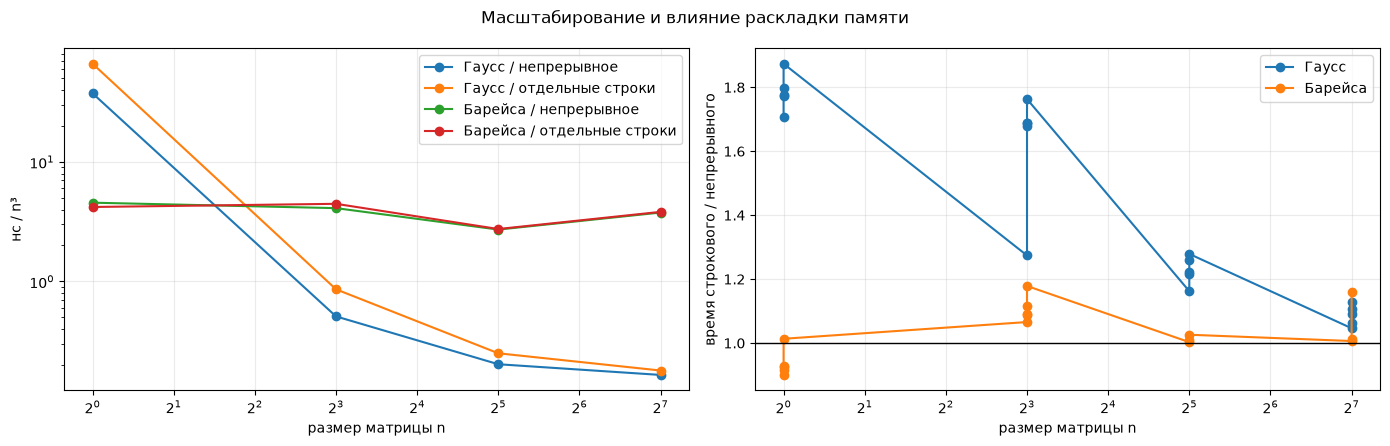

In [38]:
# Нормированное на n^3 время и отношение медиан для двух хранилищ.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for algorithm in algorithms:
    subset = [r for r in determinants if r['algorithm'] == algorithm and r['magnitude'] == '1']
    for storage in ('contiguous', 'jagged'):
        by_size = grouped([r for r in subset if r['storage'] == storage], 'size')
        xs = sorted(int(k[0]) for k in by_size)
        ys = [np.median([r['time_ns'] for r in by_size[(n,)]]) / max(n ** 3, 1) for n in xs]
        axes[0].plot(xs, ys, marker='o', label=f'{ALGORITHM_RU[algorithm]} / {STORAGE_RU[storage]}')
axes[0].set_xscale('log', base=2); axes[0].set_yscale('log'); axes[0].set_xlabel('размер матрицы n'); axes[0].set_ylabel('нс / n³'); axes[0].legend(); axes[0].grid(alpha=.25)
speed = {}
for key, rows in grouped([r for r in determinants if r['magnitude'] == '1'], 'algorithm', 'family', 'magnitude', 'size', 'storage').items():
    speed[key] = np.median([r['time_ns'] for r in rows])
for algorithm in algorithms:
    points = []
    for key, contiguous in speed.items():
        if key[0] == algorithm and key[-1] == 'contiguous':
            jagged = speed.get(key[:-1] + ('jagged',))
            if jagged: points.append((int(key[3]), jagged / contiguous))
    if points:
        points.sort(); axes[1].plot(*zip(*points), marker='o', label=ALGORITHM_RU[algorithm])
axes[1].axhline(1, color='black', linewidth=1); axes[1].set_xscale('log', base=2); axes[1].set_xlabel('размер матрицы n'); axes[1].set_ylabel('время строкового / непрерывного'); axes[1].legend(); axes[1].grid(alpha=.25)
fig.suptitle('Масштабирование и влияние раскладки памяти'); fig.tight_layout()

## 3. Откуда берётся разница между хранилищами

Слева отдельно измерены создание, последовательное заполнение и глубокое копирование матрицы. Это помогает понять, вызвана ли разница самим исключением или стоимостью выделения и копирования памяти. У строкового варианта `n + 1` выделений памяти вместо одного, поэтому создание и копирование обычно дороже.

Справа показано распределение повторов для самой большой доступной плотной матрицы каждого алгоритма: с перестановкой для Гаусса и с известным детерминантом для Барейса. Коробка отражает устойчивость результата: широкий разброс предупреждает, что единичному замеру доверять нельзя.

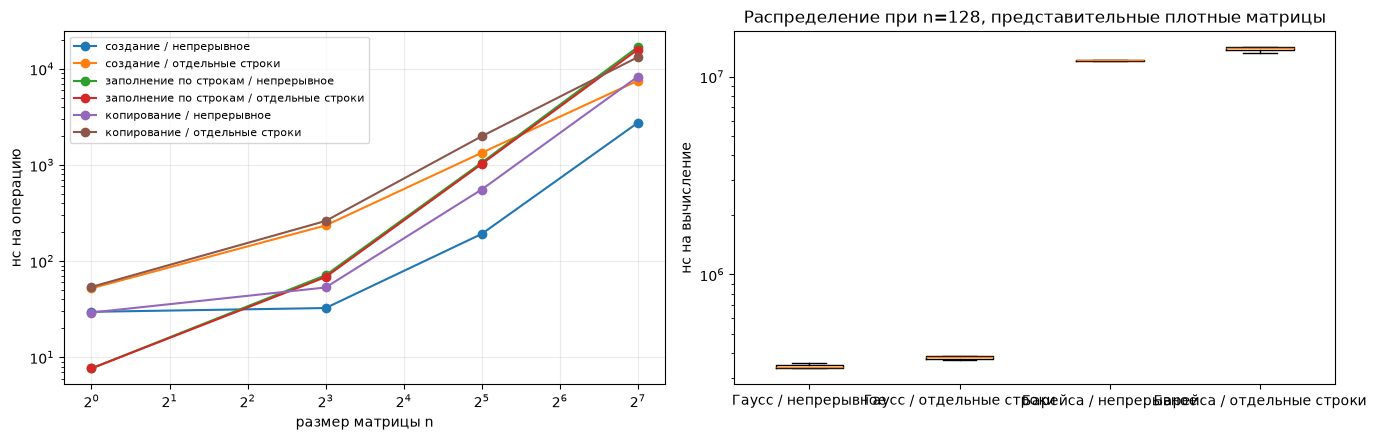

In [39]:
# Стоимость операций хранилища и распределение замеров для наибольшей матрицы.
storage_rows = [r for r in success_core if r['algorithm'] == 'storage']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for phase in ('construct', 'fill_row_major', 'copy'):
    for storage in ('contiguous', 'jagged'):
        subset = [r for r in storage_rows if r['phase'] == phase and r['storage'] == storage]
        by_size = grouped(subset, 'size')
        xs = sorted(int(k[0]) for k in by_size)
        if xs: axes[0].plot(xs, [np.median([r['time_ns'] for r in by_size[(n,)]]) for n in xs], marker='o', label=f'{PHASE_RU[phase]} / {STORAGE_RU[storage]}')
if axes[0].lines: axes[0].set_xscale('log', base=2); axes[0].set_yscale('log')
axes[0].set_xlabel('размер матрицы n'); axes[0].set_ylabel('нс на операцию');
if axes[0].lines: axes[0].legend(fontsize=8)
axes[0].grid(alpha=.25)
largest = max(r['size'] for r in determinants)
distribution = [r for r in determinants if r['size'] == largest and r['magnitude'] == '1' and ((r['algorithm'] == 'gauss' and r['family'] == 'dense_pivot') or (r['algorithm'] == 'bareiss' and r['family'] == 'dense_known'))]
labels = []; values = []
for key, rows in grouped(distribution, 'algorithm', 'storage').items(): labels.append(f'{ALGORITHM_RU[key[0]]} / {STORAGE_RU[key[1]]}'); values.append([r['time_ns'] for r in rows])
if values: axes[1].boxplot(values, tick_labels=labels); axes[1].set_yscale('log'); axes[1].set_ylabel('нс на вычисление')
axes[1].set_title(f'Распределение при n={largest}, представительные плотные матрицы'); fig.tight_layout()

## 4. Полное время CLI

Этот раздел намеренно отделён от ядра. Здесь измеряются запуск процесса, чтение текстовой матрицы, преобразование чисел, вычисление и печать ответа. На малых матрицах эти накладные расходы способны полностью скрыть различия алгоритма и раскладки памяти. Если `cli_samples.csv` отсутствует, ноутбук выводит командную подсказку вместо графика.

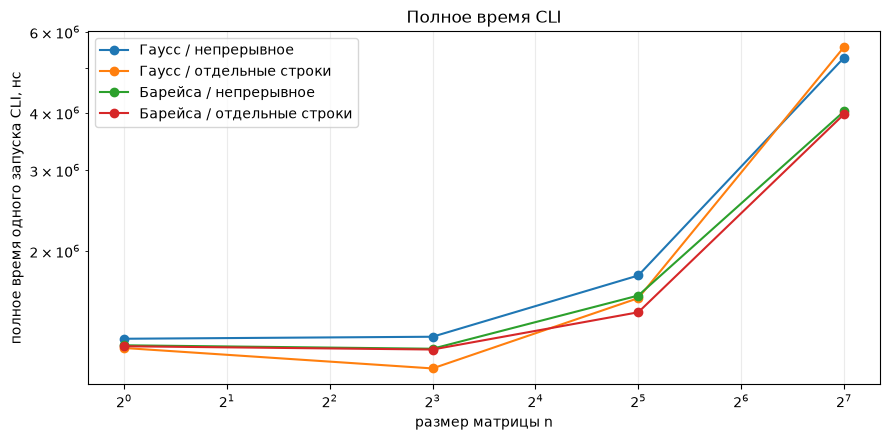

In [40]:
# CLI — отдельный эксперимент: учитываются запуск процесса, разбор, ввод и вывод.
if not cli:
    print('Данные CLI отсутствуют. Запустите scripts/run_cli_benchmarks.py, чтобы включить этот раздел.')
else:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for algorithm in algorithms:
        for storage in ('contiguous', 'jagged'):
            subset = [r for r in cli if r['algorithm'] == algorithm and r['storage'] == storage and r['status'] == 'success']
            by_size = grouped(subset, 'size'); xs = sorted(int(k[0]) for k in by_size)
            ax.plot(xs, [np.median([r['time_ns'] for r in by_size[(n,)]]) for n in xs], marker='o', label=f'{ALGORITHM_RU[algorithm]} / {STORAGE_RU[storage]}')
    ax.set_xscale('log', base=2); ax.set_yscale('log'); ax.set_xlabel('размер матрицы n'); ax.set_ylabel('полное время одного запуска CLI, нс'); ax.grid(alpha=.25); ax.legend(); ax.set_title('Полное время CLI'); fig.tight_layout()

## 5. Автоматическая сводка

Последняя ячейка формирует краткое проверяемое утверждение непосредственно из CSV: в скольких сопоставимых точках непрерывное хранение оказалось быстрее отдельно выделенных строк. Эти числа относятся только к выбранному набору результатов.

In [41]:
# Краткие выводы, вычисленные непосредственно из данных.
layout_pairs = [(value, speed[key[:-1] + ('jagged',)]) for key, value in speed.items() if key[-1] == 'contiguous' and key[:-1] + ('jagged',) in speed]
layout_wins = sum(jagged > contiguous for contiguous, jagged in layout_pairs)
print(f'Непрерывное хранилище быстрее в {layout_wins} из {len(layout_pairs)} сопоставимых агрегированных точек; детали по размерам и семействам видны на графиках.')
print('Абсолютное время корректно сравнивать только внутри этой машины, компилятора и запуска; ориентируйтесь на медианы и интервалы, а не на одиночные точки.')

Непрерывное хранилище быстрее в 32 из 36 сопоставимых агрегированных точек; детали по размерам и семействам видны на графиках.
Абсолютное время корректно сравнивать только внутри этой машины, компилятора и запуска; ориентируйтесь на медианы и интервалы, а не на одиночные точки.
